# EDA de FER-2013

Análisis exploratorio del conjunto de emociones. El cuaderno no entrena modelos ni calcula métricas de clasificación: estudia el inventario, el balance, las características visuales y los duplicados perceptuales con **dHash**.

## 1. Preparación y carga del conjunto

Las imágenes se cargan desde `data/train/<emoción>` y `data/test/<emoción>`. Mantener los dos *splits* separados permite identificar posibles coincidencias entre ambos.

In [5]:
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from skimage import color, transform, util

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
SEED = 42
ROOT = Path('data')
SPLITS = ('train', 'test')
CLASSES = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

if not all((ROOT / split).exists() for split in SPLITS):
    raise FileNotFoundError(f'No se encuentran train/test dentro de {ROOT.resolve()}')

def load_split(split):
    rows = [(path, split, label)
            for label in CLASSES
            for path in sorted((ROOT / split / label).glob('*'))
            if path.is_file()]
    df = pd.DataFrame(rows, columns=['path', 'split', 'label'])
    with ThreadPoolExecutor(max_workers=12) as executor:
        images = list(executor.map(lambda p: np.asarray(Image.open(p).convert('L')), df['path']))
    return df, np.stack(images)

df_tr, X_tr = load_split('train')
df_te, X_te = load_split('test')
print(f'Train: {X_tr.shape} | Test: {X_te.shape} | dtype: {X_tr.dtype}')
print('Rango de píxel:', X_tr.min(), '-', X_tr.max())

Train: (28709, 48, 48) | Test: (7178, 48, 48) | dtype: uint8
Rango de píxel: 0 - 255


## 2. Inventario y balance inicial por emoción

,train,test,train_%,test_%
label,,,,
angry,3995,958,13.92,13.35
disgust,436,111,1.52,1.55
fear,4097,1024,14.27,14.27
happy,7215,1774,25.13,24.71
neutral,4965,1233,17.29,17.18
sad,4830,1247,16.82,17.37
surprise,3171,831,11.05,11.58


train: 28,709 imágenes; ratio clase mayor/menor = 16.55
test: 7,178 imágenes; ratio clase mayor/menor = 15.98


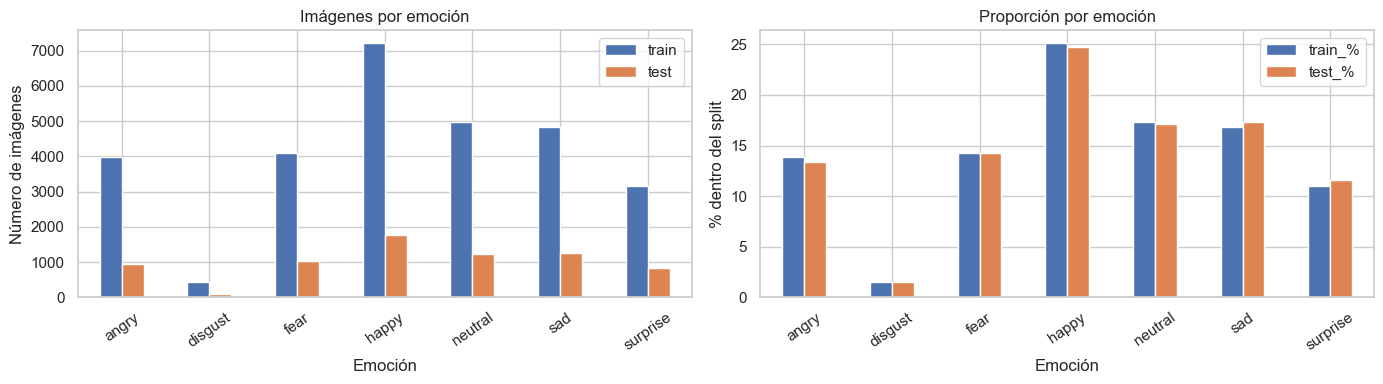

In [6]:
counts_before = pd.DataFrame({
    'train': df_tr['label'].value_counts(),
    'test': df_te['label'].value_counts(),
}).reindex(CLASSES, fill_value=0)
for split in SPLITS:
    counts_before[f'{split}_%'] = 100 * counts_before[split] / counts_before[split].sum()

display(counts_before.round(2))
for split in SPLITS:
    values = counts_before[split]
    print(f'{split}: {values.sum():,} imágenes; ratio clase mayor/menor = {values.max()/values.min():.2f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
counts_before[list(SPLITS)].plot.bar(ax=axes[0], rot=35)
axes[0].set(title='Imágenes por emoción', xlabel='Emoción', ylabel='Número de imágenes')
counts_before[[f'{split}_%' for split in SPLITS]].plot.bar(ax=axes[1], rot=35)
axes[1].set(title='Proporción por emoción', xlabel='Emoción', ylabel='% dentro del split')
plt.tight_layout()

## 3. Muestra visual y estadísticas de píxel

La inspección visual ayuda a detectar ejemplos atípicos. Se calculan brillo, contraste, entropía, rango intercuartílico y proporción de píxeles muy oscuros o muy claros para comparar las clases.

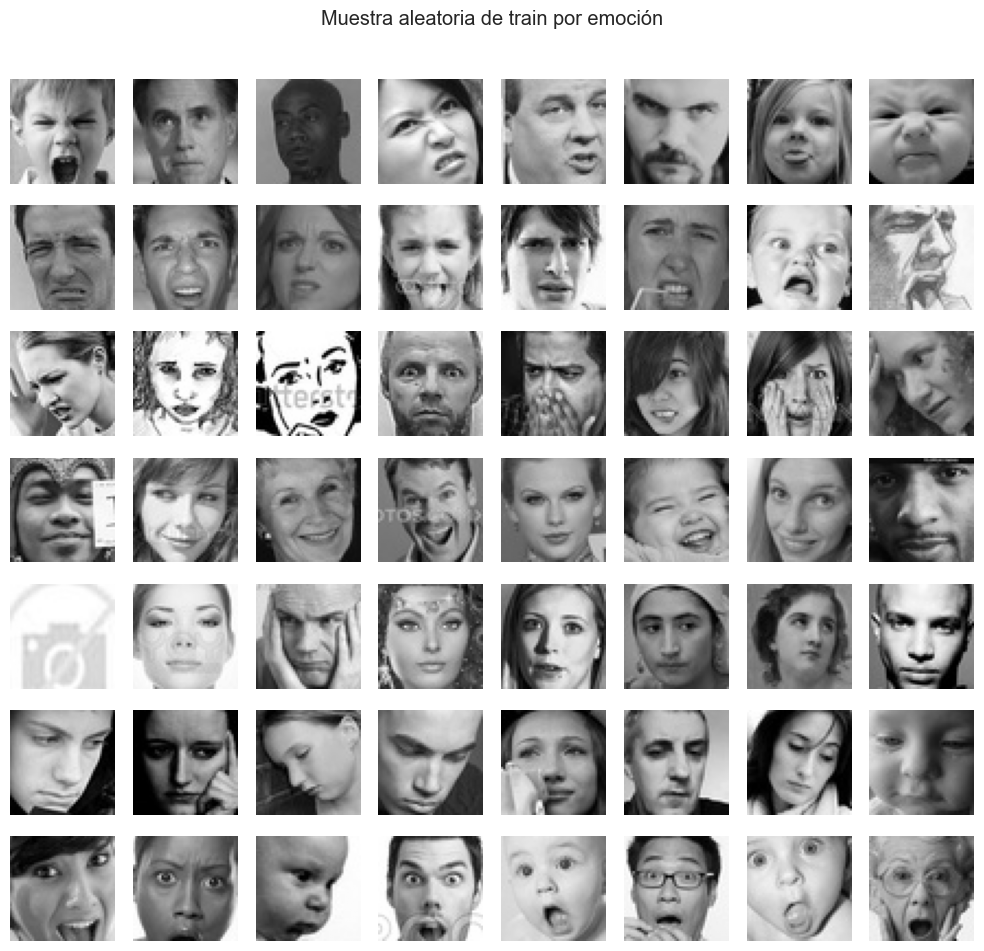

In [7]:
def show_grid(X, labels, per_class=8, seed=SEED):
    generator = np.random.default_rng(seed)
    fig, axes = plt.subplots(len(CLASSES), per_class, figsize=(per_class * 1.25, len(CLASSES) * 1.35))
    labels = np.asarray(labels)
    for row, label in enumerate(CLASSES):
        positions = np.flatnonzero(labels == label)
        selected = generator.choice(positions, size=min(per_class, len(positions)), replace=False)
        for col, pos in enumerate(selected):
            axes[row, col].imshow(X[pos], cmap='gray', vmin=0, vmax=255)
            axes[row, col].axis('off')
        axes[row, 0].set_ylabel(label, rotation=0, labelpad=30, va='center')
    fig.suptitle('Muestra aleatoria de train por emoción', y=1.01)
    plt.tight_layout()

show_grid(X_tr, df_tr['label'])

def entropy(image):
    frequencies = np.bincount(image.ravel(), minlength=256)
    probabilities = frequencies[frequencies > 0] / image.size
    return float(-(probabilities * np.log2(probabilities)).sum())

def add_pixel_features(df, X):
    flat = X.reshape(len(X), -1)
    result = df.copy()
    result['brightness'] = flat.mean(axis=1)
    result['contrast'] = flat.std(axis=1)
    result['entropy'] = [entropy(image) for image in X]
    result['iqr_intensity'] = np.percentile(flat, 75, axis=1) - np.percentile(flat, 25, axis=1)
    result['dark_pct'] = (flat < 30).mean(axis=1) * 100
    result['bright_pct'] = (flat > 225).mean(axis=1) * 100
    return result

df_tr = add_pixel_features(df_tr, X_tr)
df_te = add_pixel_features(df_te, X_te)

brightness                contrast               entropy         \
               mean  median    std     mean median    std    mean median   
label                                                                      
angry        126.23  127.16  33.17    54.42  53.97  13.71    7.25   7.33   
disgust      135.23  132.70  33.14    52.22  50.23  14.09    7.19   7.20   
fear         135.52  136.89  32.41    54.68  54.20  13.57    7.25   7.33   
happy        129.43  127.92  32.05    53.15  52.60  12.87    7.26   7.32   
neutral      123.90  123.59  33.19    54.29  54.37  14.68    7.22   7.30   
sad          121.28  121.23  33.47    53.75  52.90  14.09    7.24   7.32   
surprise     146.26  148.70  31.69    55.19  55.34  12.86    7.25   7.33   

               iqr_intensity               dark_pct               bright_pct  \
           std          mean median    std     mean median    std       mean   
label                                                                          
angry     0.50         83.59   79.0  33.34     8.79   4.73  11.08       5.83   
disgust   0.40         78.07   69.0  34.16     6.57   3.75   8.05       6.07   
fear      0.39         83.05   78.0  33.94     7.20   3.43   9.55       6.96   
happy     0.36         81.46   77.0  32.17     7.60   4.17   9.24       5.32   
neutral   0.42         84.80   81.0  36.35     9.02   4.73  10.98       5.28   
sad       0.39         83.66   78.0  34.67    10.06   5.38  12.17       4.61   
surprise  0.42         82.61   80.0  33.38     5.74   2.43   7.80       9.03   

                        
         median    std  
label                   
angry      1.35   9.42  
disgust    1.26   9.44  
fear       2.91   9.92  
happy      0.95   9.19  
neutral    1.00   8.89  
sad        0.78   8.16  
surprise   5.21  11.07

,variable,eta_squared
0,brightness,0.0490
5,bright_pct,0.0188
4,dark_pct,0.0157
1,contrast,0.0027
3,iqr_intensity,0.0014
2,entropy,0.0013


Imágenes de train marcadas para revisión por bajo contraste o brillo extremo: 33


,label,brightness,contrast,entropy,path
2,angry,0.000000,0.000000,-0.000000,data\train\angry\Training_10131352.jpg
690,angry,10.634983,42.519920,1.432883,data\train\angry\Training_25739285.jpg
838,angry,0.000000,0.000000,-0.000000,data\train\angry\Training_28756096.jpg
1002,angry,0.000000,0.000000,-0.000000,data\train\angry\Training_32571770.jpg
1882,angry,0.000000,0.000000,-0.000000,data\train\angry\Training_52563817.jpg
2062,angry,5.354601,31.962117,0.810075,data\train\angry\Training_5645946.jpg
2541,angry,240.880642,23.142581,4.247123,data\train\angry\Training_67604214.jpg
3006,angry,0.000000,0.000000,-0.000000,data\train\angry\Training_78540321.jpg
3431,angry,244.684028,20.852574,3.630504,data\train\angry\Training_87875595.jpg
3664,angry,240.855035,28.255112,3.952521,data\train\angry\Training_93307158.jpg


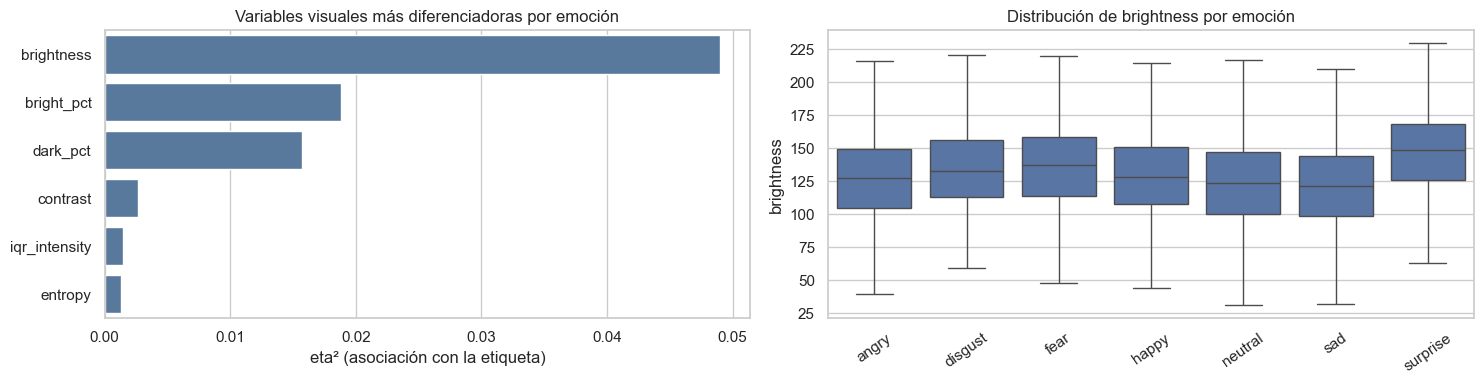

In [8]:
FEATURES = ['brightness', 'contrast', 'entropy', 'iqr_intensity', 'dark_pct', 'bright_pct']

# Tamaño de efecto eta²: proporción de variabilidad de cada medida explicada por la etiqueta.
def eta_squared(data, feature):
    overall_mean = data[feature].mean()
    between = sum(len(group) * (group[feature].mean() - overall_mean) ** 2
                  for _, group in data.groupby('label'))
    total = ((data[feature] - overall_mean) ** 2).sum()
    return between / total if total else 0.0

feature_summary = df_tr.groupby('label')[FEATURES].agg(['mean', 'median', 'std']).reindex(CLASSES)
display(feature_summary.round(2))

importance = pd.DataFrame({'variable': FEATURES, 'eta_squared': [eta_squared(df_tr, f) for f in FEATURES]})
importance = importance.sort_values('eta_squared', ascending=False)
display(importance.style.format({'eta_squared': '{:.4f}'}))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.barplot(data=importance, x='eta_squared', y='variable', color='#4C78A8', ax=axes[0])
axes[0].set(title='Variables visuales más diferenciadoras por emoción', xlabel='eta² (asociación con la etiqueta)', ylabel='')
top_features = importance.head(2)['variable'].tolist()
for feature in top_features:
    pass
sns.boxplot(data=df_tr, x='label', y=top_features[0], order=CLASSES, showfliers=False, ax=axes[1])
axes[1].set(title=f'Distribución de {top_features[0]} por emoción', xlabel='')
axes[1].tick_params(axis='x', rotation=35)
plt.tight_layout()

quality_flags = df_tr.query('contrast < 5 or brightness < 15 or brightness > 240')
print(f'Imágenes de train marcadas para revisión por bajo contraste o brillo extremo: {len(quality_flags):,}')
display(quality_flags[['label', 'brightness', 'contrast', 'entropy', 'path']].head(15))

## 4. Duplicados perceptuales con dHash

Se utiliza la misma función `dhash` del cuaderno de indexado: convierte a gris, redimensiona a 8×9 y compara cada píxel con su vecino derecho. Aquí se consideran duplicados candidatos los hashes exactamente iguales (distancia de Hamming 0). Un mismo dHash indica similitud perceptual; los casos que mezclan etiquetas se marcan para revisión y **no** se eliminan automáticamente.

In [9]:
# Función tomada del cuaderno T3_4_indexado_recuperacion.ipynb
def dhash(im, s=8):
    g = color.rgb2gray(im) if im.ndim == 3 else util.img_as_float(im)
    g = transform.resize(g, (s, s + 1), anti_aliasing=True)
    return (g[:, 1:] > g[:, :-1]).ravel()

def dhash_key(image):
    # Convierte los 64 bits a texto para agruparlos en pandas.
    return np.packbits(dhash(image)).tobytes().hex()

df_tr['dhash'] = [dhash_key(image) for image in X_tr]
df_te['dhash'] = [dhash_key(image) for image in X_te]
df_all = pd.concat([df_tr, df_te], ignore_index=True)

hash_groups = (df_all.groupby(['split', 'dhash'])
               .agg(n_images=('path', 'size'), n_labels=('label', 'nunique'),
                    labels=('label', lambda values: ', '.join(sorted(set(values)))))
               .reset_index())
repeated_groups = hash_groups.query('n_images > 1').copy()
cross_split_hashes = df_all.groupby('dhash')['split'].nunique()
cross_split_hashes = cross_split_hashes[cross_split_hashes > 1].index

duplicate_report = pd.DataFrame(index=SPLITS)
duplicate_report['imágenes'] = df_all.groupby('split').size()
duplicate_report['hashes_dhash_únicos'] = df_all.groupby('split')['dhash'].nunique()
duplicate_report['grupos_repetidos'] = repeated_groups.groupby('split').size()
duplicate_report['imágenes_en_grupos_repetidos'] = (df_all[df_all.duplicated(['split', 'dhash'], keep=False)]
                                                    .groupby('split').size())
duplicate_report['grupos_multietiqueta'] = repeated_groups.query('n_labels > 1').groupby('split').size()
display(duplicate_report.fillna(0).astype(int))
print(f'Hashes dHash presentes tanto en train como en test: {len(cross_split_hashes):,}')
display(repeated_groups.sort_values(['n_labels', 'n_images'], ascending=False).head(20))

,imágenes,hashes_dhash_únicos,grupos_repetidos,imágenes_en_grupos_repetidos,grupos_multietiqueta
train,28709,27367,1103,2445,58
test,7178,7075,97,200,6


Hashes dHash presentes tanto en train como en test: 581


,split,dhash,n_images,n_labels,labels
7075,train,0000000000000000,11,5,"angry, happy, neutral, sad, surprise"
29114,train,f0f0f0f0d4d4f0f0,4,3,"happy, neutral, surprise"
13585,train,5b9dbedadedccc1c,6,2,"fear, surprise"
32570,train,f8fcf2f6dcdcfa7f,5,2,"fear, surprise"
7493,train,0301406151301000,4,2,"fear, surprise"
12133,train,3b39392d2d393939,4,2,"disgust, surprise"
25525,train,e0f09094848cc4e4,4,2,"disgust, fear"
5782,test,f0f1b9b386848cc8,3,2,"fear, sad"
7639,train,036321191010110d,3,2,"fear, neutral"
9955,train,23031533070f0f23,3,2,"angry, sad"


Grupos dHash de train con más de una etiqueta:


,dhash,n_images,labels
7075,0000000000000000,11,"angry, happy, neutral, sad, surprise"
7493,0301406151301000,4,"fear, surprise"
7639,036321191010110d,3,"fear, neutral"
9890,21613737050d0766,2,"angry, fear"
9955,23031533070f0f23,3,"angry, sad"
12133,3b39392d2d393939,4,"disgust, surprise"
12406,3ce5d2ee78393b97,2,"angry, sad"
12643,3f333b3b1b1f1d3f,2,"angry, sad"
12954,4140b0b0c48484e1,3,"angry, sad"
13291,4c1e16365e5c7c5e,3,"fear, surprise"


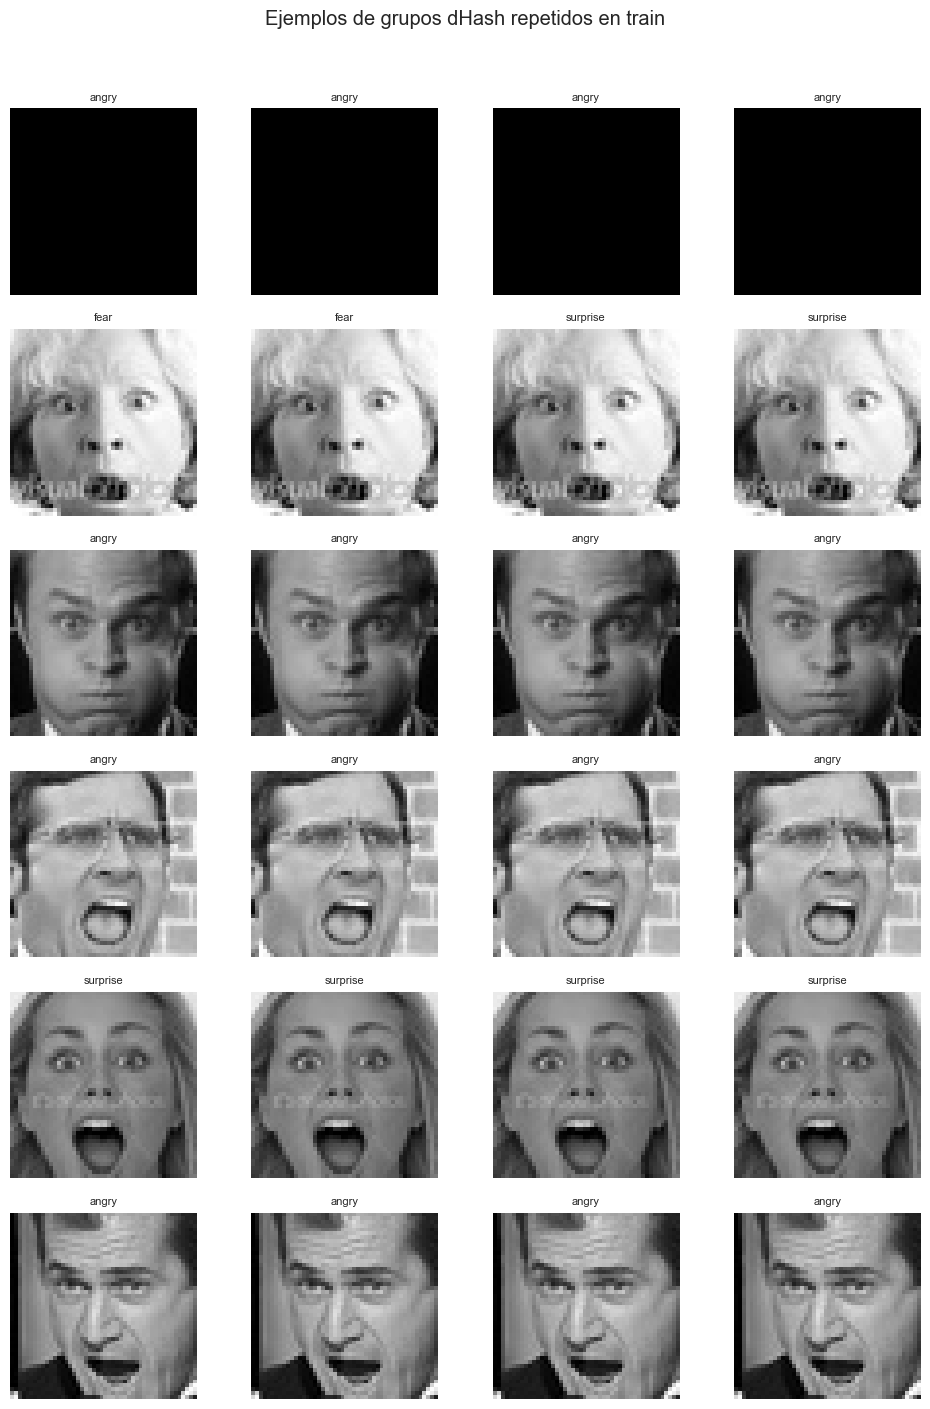

In [10]:
def show_duplicate_examples(df, X, n_groups=6, max_per_group=4):
    group_sizes = df.groupby('dhash').size().sort_values(ascending=False)
    group_ids = group_sizes[group_sizes > 1].head(n_groups).index.tolist()
    if not group_ids:
        print('No hay duplicados dHash dentro de este split.')
        return
    fig, axes = plt.subplots(len(group_ids), max_per_group, figsize=(2.5 * max_per_group, 2.3 * len(group_ids)), squeeze=False)
    for row, hash_value in enumerate(group_ids):
        positions = df.index[df['dhash'].eq(hash_value)].tolist()[:max_per_group]
        for col, pos in enumerate(positions):
            axes[row, col].imshow(X[pos], cmap='gray', vmin=0, vmax=255)
            axes[row, col].set_title(df.loc[pos, 'label'], fontsize=8)
        for ax in axes[row]:
            ax.axis('off')
        axes[row, 0].set_ylabel(f'{hash_value}\nn={len(positions)}', rotation=0, ha='right', va='center', fontsize=7)
    fig.suptitle('Ejemplos de grupos dHash repetidos en train', y=1.02)
    plt.tight_layout()

show_duplicate_examples(df_tr, X_tr)

conflicting_train = repeated_groups.query("split == 'train' and n_labels > 1")
if not conflicting_train.empty:
    print('Grupos dHash de train con más de una etiqueta:')
    display(conflicting_train[['dhash', 'n_images', 'labels']])
else:
    print('No hay grupos repetidos con etiquetas distintas en train.')

## 5. ¿Cuántas imágenes quedan por clase tras quitar duplicados?

La deduplicación es únicamente un escenario descriptivo: se conserva la primera imagen de cada grupo `(split, dHash)` cuando todas comparten la misma etiqueta. Los grupos multietiqueta se mantienen íntegros para no decidir arbitrariamente qué emoción es correcta. El conjunto de archivos no se modifica.

In [11]:
def conservative_dedup(df):
    result = df.copy()
    same_label_group = result.groupby(['split', 'dhash'])['label'].transform('nunique').eq(1)
    later_copy = result.duplicated(['split', 'dhash'], keep='first')
    result['remove_dhash'] = same_label_group & later_copy
    return result

df_all_dedup = conservative_dedup(df_all)
df_clean = df_all_dedup.loc[~df_all_dedup['remove_dhash']].copy()

before = df_all.groupby(['split', 'label']).size().rename('antes')
after = df_clean.groupby(['split', 'label']).size().rename('después')
class_impact = pd.concat([before, after], axis=1).reindex(
    pd.MultiIndex.from_product([SPLITS, CLASSES], names=['split', 'label']), fill_value=0
).fillna(0).astype(int)
class_impact['eliminadas'] = class_impact['antes'] - class_impact['después']
class_impact['eliminadas_%'] = 100 * class_impact['eliminadas'] / class_impact['antes']
class_impact['proporción_final_%'] = class_impact.groupby(level='split')['después'].transform(lambda x: 100 * x / x.sum())
display(class_impact.round(2))

split_impact = pd.DataFrame({'antes': df_all.groupby('split').size(), 'después': df_clean.groupby('split').size()}).reindex(SPLITS)
split_impact['eliminadas'] = split_impact['antes'] - split_impact['después']
split_impact['eliminadas_%'] = 100 * split_impact['eliminadas'] / split_impact['antes']
display(split_impact.round(2))

class_summary = (class_impact.xs('train')
                 .join(df_tr.groupby('label')[['brightness', 'contrast', 'entropy']].mean())
                 .reindex(CLASSES))
class_summary['ratio_frente_a_clase_menor_final'] = class_summary['después'] / class_summary['después'].min()
display(class_summary.round(2))

antes  después  eliminadas  eliminadas_%  proporción_final_%
split label                                                                 
train angry      3995     3838         157          3.93               13.97
      disgust     436      379          57         13.07                1.38
      fear       4097     3898         199          4.86               14.19
      happy      7215     7085         130          1.80               25.80
      neutral    4965     4871          94          1.89               17.74
      sad        4830     4721         109          2.26               17.19
      surprise   3171     2672         499         15.74                9.73
test  angry       958      943          15          1.57               13.32
      disgust     111      109           2          1.80                1.54
      fear       1024     1011          13          1.27               14.28
      happy      1774     1765           9          0.51               24.92
      neutral    1233     1223          10          0.81               17.27
      sad        1247     1240           7          0.56               17.51
      surprise    831      791          40          4.81               11.17

,antes,después,eliminadas,eliminadas_%
split,,,,
train,28709,27464,1245,4.34
test,7178,7082,96,1.34


,antes,después,eliminadas,eliminadas_%,proporción_final_%,brightness,contrast,entropy,ratio_frente_a_clase_menor_final
label,,,,,,,,,
angry,3995,3838,157,3.93,13.97,126.23,54.42,7.25,10.13
disgust,436,379,57,13.07,1.38,135.23,52.22,7.19,1.00
fear,4097,3898,199,4.86,14.19,135.52,54.68,7.25,10.28
happy,7215,7085,130,1.80,25.80,129.43,53.15,7.26,18.69
neutral,4965,4871,94,1.89,17.74,123.90,54.29,7.22,12.85
sad,4830,4721,109,2.26,17.19,121.28,53.75,7.24,12.46
surprise,3171,2672,499,15.74,9.73,146.26,55.19,7.25,7.05


Variables visuales más diferenciadoras (eta²):


,variable,eta_squared
0,brightness,0.0490
5,bright_pct,0.0188
4,dark_pct,0.0157
1,contrast,0.0027
3,iqr_intensity,0.0014


Recuerda revisar visualmente los grupos dHash y las coincidencias train/test antes de eliminar archivos.


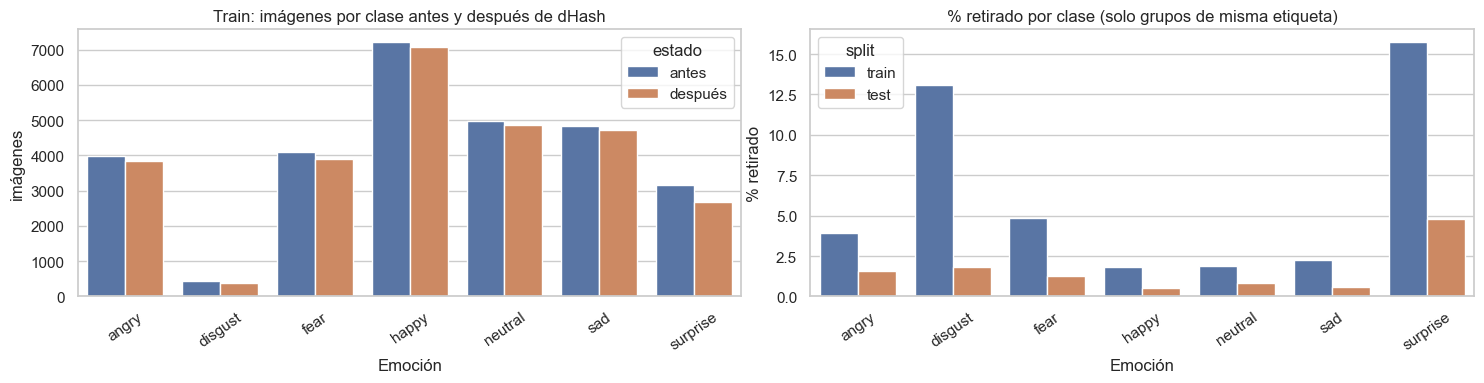

In [12]:
plot_data = class_impact.reset_index().melt(
    id_vars=['split', 'label'], value_vars=['antes', 'después'],
    var_name='estado', value_name='imágenes')
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.barplot(data=plot_data.query("split == 'train'"), x='label', y='imágenes', hue='estado', ax=axes[0])
axes[0].set(title='Train: imágenes por clase antes y después de dHash', xlabel='Emoción')
axes[0].tick_params(axis='x', rotation=35)
sns.barplot(data=class_impact.reset_index(), x='label', y='eliminadas_%', hue='split', ax=axes[1])
axes[1].set(title='% retirado por clase (solo grupos de misma etiqueta)', xlabel='Emoción', ylabel='% retirado')
axes[1].tick_params(axis='x', rotation=35)
plt.tight_layout()

print('Variables visuales más diferenciadoras (eta²):')
display(importance.head(5).style.format({'eta_squared': '{:.4f}'}))
print('Recuerda revisar visualmente los grupos dHash y las coincidencias train/test antes de eliminar archivos.')

## Resumen

Este EDA deja documentados el desbalance de las emociones, las diferencias descriptivas entre clases, la calidad básica de las imágenes y el efecto de retirar duplicados perceptuales. No se realiza ninguna eliminación de archivos, entrenamiento ni evaluación de modelos.